# Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
df= pd.read_csv("/content/customer_churn_clean_data.csv",na_values=["?"])

df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [ ]:
df.shape

(440833, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440833 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  object 
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  object 
 8   Contract Length    440832 non-null  object 
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), object(3)
memory usage: 40.4+ MB


In [ ]:
df.isnull().sum()

,0
CustomerID,1
Age,1
Gender,1
Tenure,1
Usage Frequency,1
Support Calls,1
Payment Delay,1
Subscription Type,1
Contract Length,1
Total Spend,1


In [ ]:
df.dropna(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000
mean,225398.667955,39.373153,31.256336,15.807494,3.604437,12.965722,631.616223,14.480868,0.567107
std,129531.918550,12.442369,17.255727,8.586242,3.070218,8.258063,240.803001,8.596208,0.495477
min,2.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,113621.750000,29.000000,16.000000,9.000000,1.000000,6.000000,480.000000,7.000000,0.000000
50%,226125.500000,39.000000,32.000000,16.000000,3.000000,12.000000,661.000000,14.000000,1.000000
75%,337739.250000,48.000000,46.000000,23.000000,6.000000,19.000000,830.000000,22.000000,1.000000
max,449999.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [ ]:
print("Columns:", df.columns.tolist())

Columns: ['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction', 'Churn']


In [ ]:
df['Churn'].value_counts()

,count
Churn,
1.0,249999
0.0,190833


In [ ]:
df.drop('CustomerID', axis=1, inplace=True)

# EDA

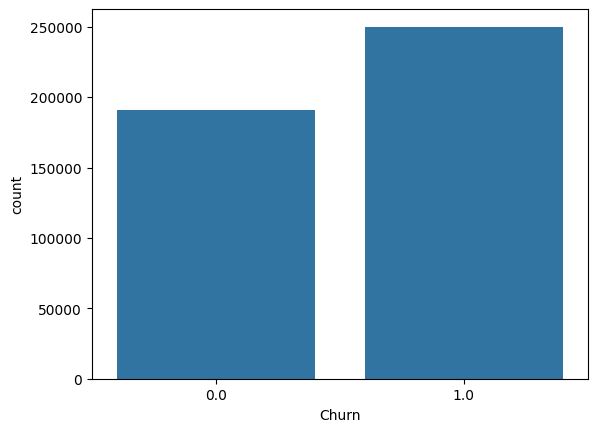

In [ ]:
#Count Plot = frequency of each category in a categorical column.
# no imbalance
sns.countplot(x='Churn', data=df)
plt.show()

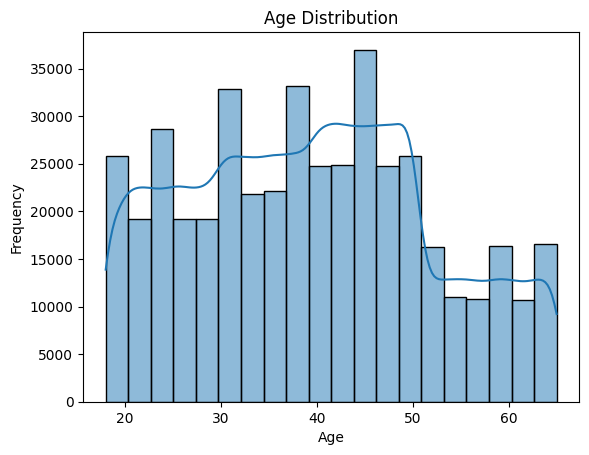

In [ ]:
#histogram=one numerical column
sns.histplot(df['Age'], bins=20 , kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

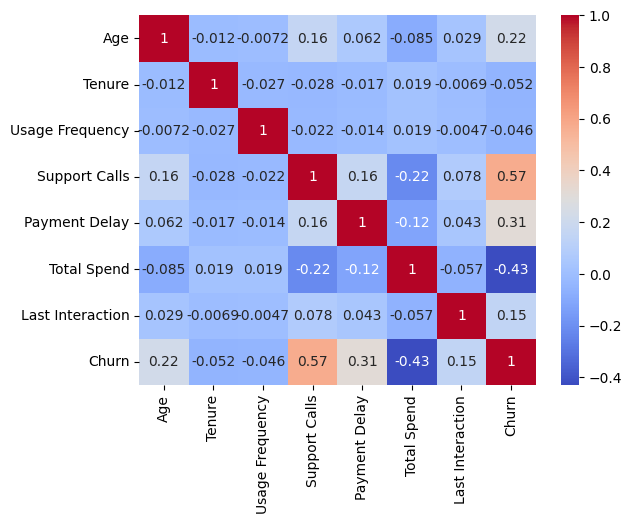

In [ ]:
#heatmap_Correlation=Numerical Columns
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

# spliting


In [ ]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [ ]:
# no imbalance--> no class_weight --> no smoot
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

In [ ]:
num_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler())
])
#StandardScaler (مع الارقام ) ---> علشان نخلي المتوسط بتاع الارقام بين ال 0 و ال1 علشان تطلع النسب صحيحه

cat_pipeline = Pipeline(steps=[
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])
# OneHotEncoder(مع الحروف) ---> بيزود ال features بس بيظبط ال acc
# drop=first ---> علشان يشيل عمود واحد يعني يطلع male او female

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# Random forest

In [ ]:
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42,n_jobs=-1))
])

In [ ]:
rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(random_state=42, n_estimators=200,n_jobs=-1))
    ]
)

In [ ]:
start_time = time.time()
rf_pipeline.fit(X_train, y_train)
train_time = time.time() - start_time

In [ ]:
train_acc = rf_pipeline.score(X_train, y_train)
test_acc = rf_pipeline.score(X_test, y_test)

In [ ]:
y_pred_train = rf_pipeline.predict(X_train)
y_pred_test = rf_pipeline.predict(X_test)

In [ ]:
print("--- Baseline Random Forest Evaluation Report ---")
print(f"Training Time: {train_time:.2f} seconds\n")

print(f"Train Accuracy: {accuracy_score(y_train, y_pred_train) * 100:.2f}%")
print(f"Test Accuracy:  {accuracy_score(y_test, y_pred_test) * 100:.2f}%\n")

print("--- Classification Report (Test Data) ---")
print(classification_report(y_test, y_pred_test))

--- Baseline Random Forest Evaluation Report ---
Training Time: 60.93 seconds

Train Accuracy: 100.00%
Test Accuracy:  99.96%

--- Classification Report (Test Data) ---
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     38063
         1.0       1.00      1.00      1.00     50104

    accuracy                           1.00     88167
   macro avg       1.00      1.00      1.00     88167
weighted avg       1.00      1.00      1.00     88167



# XGBOST


In [ ]:
!pip install xgboost

In [ ]:
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss',n_estimators=200))
])

In [ ]:
start_time = time.time()
xgb_pipeline.fit(X_train, y_train)
train_time = time.time() - start_time

In [ ]:
train_acc = xgb_pipeline.score(X_train, y_train)
test_acc = xgb_pipeline.score(X_test, y_test)

In [ ]:
y_pred_train = xgb_pipeline.predict(X_train)
y_pred_test = xgb_pipeline.predict(X_test)

In [ ]:
print("--- Baseline XGBoost Evaluation Report ---")
print(f"Training Time: {train_time:.2f} seconds\n")

print(f"Train Accuracy: {accuracy_score(y_train, y_pred_train) * 100:.2f}%")
print(f"Test Accuracy:  {accuracy_score(y_test, y_pred_test) * 100:.2f}%\n")

print("--- Classification Report (Test Data) ---")
print(classification_report(y_test, y_pred_test))

--- Baseline XGBoost Evaluation Report ---
Training Time: 5.08 seconds

Train Accuracy: 100.00%
Test Accuracy:  99.98%

--- Classification Report (Test Data) ---
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     38063
         1.0       1.00      1.00      1.00     50104

    accuracy                           1.00     88167
   macro avg       1.00      1.00      1.00     88167
weighted avg       1.00      1.00      1.00     88167

